In [ ]:
pip install axelrod
pip install nashpy

In [6]:
import axelrod as axl
import nashpy as nash
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# Classic Prisoner's Dilemma payoff matrix for AI frontier Lab 1 and Lab 2

row_strategies = ["Cooperate (Safe)", "Defect (Race)"]
col_strategies = ["Cooperate (Safe)", "Defect (Race)"]

frontier_lab1 = np.array([[3,0], [5, 1]])
frontier_lab2 = np.array([[3,5], [0, 1]])

game = nash.Game(frontier_lab1, frontier_lab2)
equilibria = game.support_enumeration()
print("\nNash Equilibria for the game:")
for eq in equilibria:
    print(eq)


Nash Equilibria for the game:
(array([0., 1.]), array([0., 1.]))


In [7]:
payoff_matrix = pd.DataFrame(
    [
        [
            (frontier_lab1[i, j], frontier_lab2[i, j])
            for j in range(len(col_strategies))
        ]
        for i in range(len(row_strategies))
    ],
    index=pd.Index(row_strategies, name="Lab 1 / Lab 2"),
    columns=col_strategies,
)

print("Payoff matrix (Lab 1, Lab 2):")
print(payoff_matrix.to_string())


Payoff matrix (Lab 1, Lab 2):
                 Cooperate (Safe) Defect (Race)
Lab 1 / Lab 2                                  
Cooperate (Safe)           (3, 3)        (0, 5)
Defect (Race)              (5, 0)        (1, 1)


In [8]:
# Display equilibria with strategy names and probabilities
print("\nNash Equilibria for the game:")
for row_probs, col_probs in game.support_enumeration():
    for lab, strategies, probs in [
        ("Lab 1", row_strategies, row_probs),
        ("Lab 2", col_strategies, col_probs),
    ]:
        choices = ", ".join(
            f"{strategy}: {prob:.0%}"
            for strategy, prob in zip(strategies, probs)
        )
        print(f"{lab}: {choices}")


Nash Equilibria for the game:
Lab 1: Cooperate (Safe): 0%, Defect (Race): 100%
Lab 2: Cooperate (Safe): 0%, Defect (Race): 100%


In [24]:
game_iterated = axl.Game(r=3, s=0, t=5, p=1)

players = [
    axl.Cooperator(),   # Always cooperates (prioritizes safety)
    axl.Defector(),     # Always defects (prioritizes speed)
    axl.TitForTat(),    # Cooperates first, then copies opponent
    axl.Grudger(),      # Cooperates until opponent defects
    axl.Random(),      # Randomly cooperates or defects
]

tournament = axl.Tournament(
    players,
    game=game_iterated,
    turns=200,        # Rounds per match
    repetitions=10,   # Repeat each matchup
    seed=42,          # Reproducible randomness
)
results = tournament.play()

print("Ranking:", results.ranked_names)
print("Average payoff per turn against each opponent:")
for player, row in zip(players, results.payoff_matrix):
    print(f"{str(player):15}: {row}")


Analysing: 100%|██████████| 25/25 [00:00<00:00, 311.42it/s]

Ranking: ['Defector', 'Grudger', 'Tit For Tat', 'Cooperator', 'Random: 0.5']
Average payoff per turn against each opponent:
Cooperator     : [np.float64(3.0), np.float64(0.0), np.float64(3.0), np.float64(3.0), np.float64(1.4685)]
Defector       : [np.float64(5.0), np.float64(1.0), np.float64(1.02), np.float64(1.02), np.float64(2.9840000000000004)]
Tit For Tat    : [np.float64(3.0), np.float64(0.9949999999999999), np.float64(3.0), np.float64(3.0), np.float64(2.239)]
Grudger        : [np.float64(3.0), np.float64(0.9949999999999999), np.float64(3.0), np.float64(3.0), np.float64(2.997)]
Random: 0.5    : [np.float64(4.021), np.float64(0.5039999999999999), np.float64(2.254), np.float64(0.5369999999999999), np.float64(2.2384999999999997)]


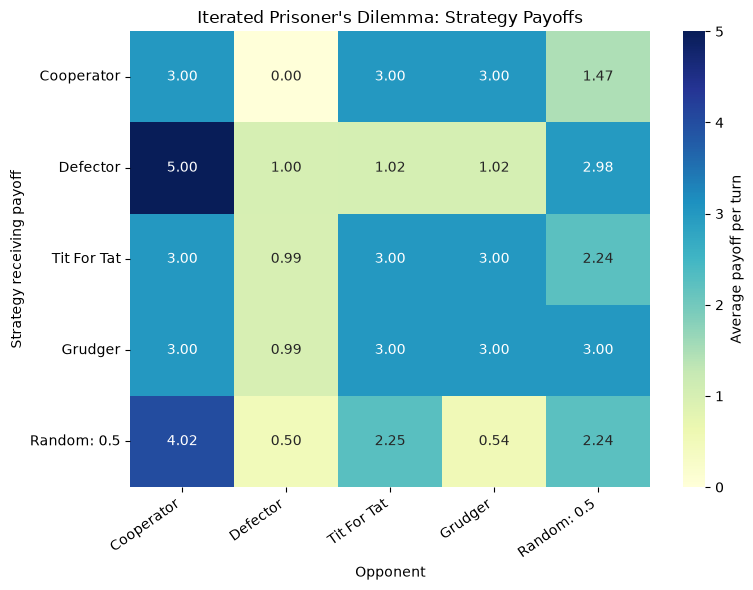

In [28]:
names = [str(player) for player in players]

fig, ax = plt.subplots(figsize=(8, 6))

sns.heatmap(
    results.payoff_matrix,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    xticklabels=names,
    yticklabels=names,
    cbar_kws={"label": "Average payoff per turn"},
    ax=ax,
)

ax.set(
    title="Iterated Prisoner's Dilemma: Strategy Payoffs",
    xlabel="Opponent",
    ylabel="Strategy receiving payoff",
)

plt.xticks(rotation=35, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()